In [109]:
import torch
# from torch import nn
from torch.nn.parameter import Parameter
import torch.nn.functional as F
import torch.optim as optim
import torch.nn.init as init

%matplotlib inline
import matplotlib
import matplotlib.pyplot as plt

## Task 2

Creating the closed form solution in pytorch

In [110]:
m = 1
mu = 5
k = 500

delta = torch.tensor(mu/(2*m))
w0 = torch.sqrt(torch.tensor(k))
w = torch.sqrt(w0**2 - delta**2)

phi = torch.atan(-delta/w)
A = 1/(2*torch.cos(phi))

def x(t):
    return torch.exp(-delta*t)*(2*A*torch.cos(phi + w*t))

### Task 2.1

Generating training data

In [111]:
n_train = 10

x_train = torch.rand(10) * 0.5  # to get the data points in the interval [0, 0.5]
target_train = torch.tensor([x(t) for t in x_train])    # to get the actual values of x(t)

print(x_train)
print(target_train)

tensor([0.4750, 0.0425, 0.3957, 0.4128, 0.0923, 0.1181, 0.0156, 0.2139, 0.4297,
        0.2873])
tensor([-0.1613,  0.6091, -0.2751, -0.3350, -0.2880, -0.6052,  0.9412, -0.0427,
        -0.3436,  0.4907])


### Task 2.2

Train a simple neural network with the training data

In [112]:
simple_model = torch.nn.Sequential(
    torch.nn.Linear(1, 10),
    torch.nn.Tanh(),
    torch.nn.Linear(10, 1)
)

# net = simple_model

In [113]:
better_model = torch.nn.Sequential(
    torch.nn.Linear(1, 32),
    torch.nn.ReLU(),
    torch.nn.Linear(32, 64),
    torch.nn.ReLU(),
    torch.nn.Linear(64, 128),
    torch.nn.ReLU(),
    torch.nn.Linear(128, 1)
)

# net = better_model

Epoch  1 : Train Loss 0.024237
Epoch 11 : Train Loss 0.022977
Epoch 21 : Train Loss 0.022554
Epoch 31 : Train Loss 0.022237
Epoch 41 : Train Loss 0.021887
Epoch 51 : Train Loss 0.021559
Epoch 61 : Train Loss 0.021241
Epoch 71 : Train Loss 0.020930
Epoch 81 : Train Loss 0.020632
Epoch 91 : Train Loss 0.020345
Epoch 101 : Train Loss 0.020071
Epoch 111 : Train Loss 0.019809
Epoch 121 : Train Loss 0.019561
Epoch 131 : Train Loss 0.019326
Epoch 141 : Train Loss 0.019104
Epoch 151 : Train Loss 0.018897
Epoch 161 : Train Loss 0.018704
Epoch 171 : Train Loss 0.018524
Epoch 181 : Train Loss 0.018359
Epoch 191 : Train Loss 0.018208


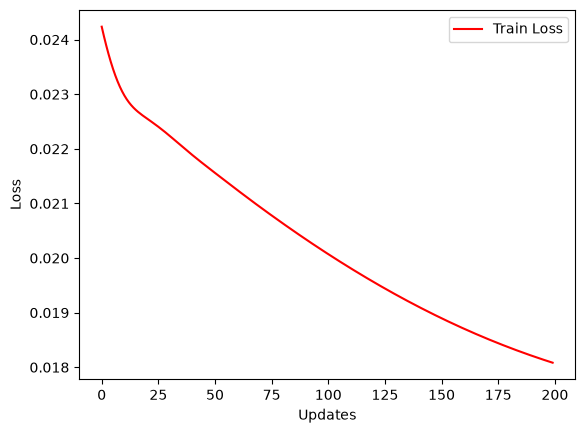

In [114]:
# choose the model
net = simple_model

# choose the optimizer and loss function
optimizer = optim.Adam(net.parameters(), lr=0.001)
criterion = torch.nn.MSELoss()

# changing the shape of the data
x_train = x_train.reshape(len(x_train),1)
target_train = target_train.reshape(len(target_train),1)

# setting hyperparameters and gettings epoch sizes
batch_size = 10
num_epochs = 200
num_samples_train = len(x_train)
num_batches_train = num_samples_train // batch_size
# num_samples_valid = len(target_val)
# num_batches_valid = num_samples_valid // batch_size

# setting up lists for handling loss/accuracy
train_acc, train_loss = [], []
# valid_acc, valid_loss = [], []
test_acc, test_loss = [], []
cur_loss = 0
losses = []

get_slice = lambda i, size: range(i * size, (i + 1) * size)

for epoch in range(num_epochs):
    # Forward -> Backprob -> Update params
    ## Train
    cur_loss = 0
    net.train()
    for i in range(num_batches_train):
        optimizer.zero_grad()
        slce = get_slice(i, batch_size)
        output = net(x_train[slce])
        
        # compute gradients given loss
        target_batch = target_train[slce]
        batch_loss = criterion(output, target_batch)
        batch_loss.backward()
        optimizer.step()
        
        cur_loss += batch_loss.item()
    losses.append(cur_loss / batch_size)

    net.eval()
    ### Evaluate training
    train_preds, train_targs = [], []
    for i in range(num_batches_train):
        slce = get_slice(i, batch_size)
        output = net(x_train[slce])

        preds = output
        # preds = torch.max(output, 1)[1]
        
        train_targs += list(target_train[slce].numpy())
        train_preds += list(preds.data.numpy())
        
    
    if epoch % 10 == 0:
        print("Epoch %2i : Train Loss %f" % (
                epoch+1, losses[-1]))

epoch = torch.arange(epoch + 1)
plt.figure()
plt.plot(epoch, losses, 'r')
plt.legend(['Train Loss'])
plt.xlabel('Updates')
plt.ylabel('Loss')
plt.show()

In [115]:
n_val = 100

x_val = torch.arange(0, 1, 1/n_val)      # to get the data points in the interval [0, 1]
target_val = torch.tensor([x(t) for t in x_val])    # to get the actual values of x(t)

# print(x_val)
# print(target_val)

(Text(0.5, 0, 't'), Text(0, 0.5, 'Loss'))

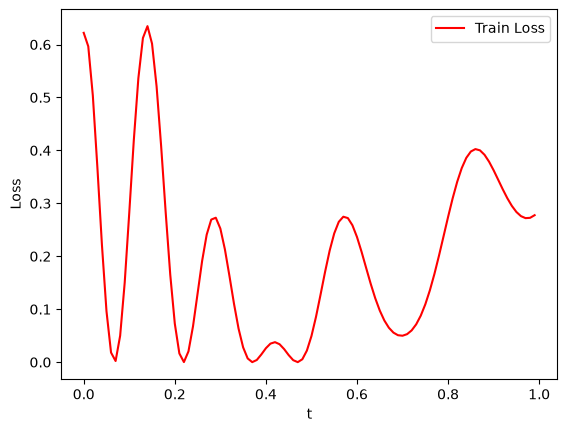

In [116]:
x_val = x_val.reshape(len(x_val),1)
target_val = target_val.reshape(len(target_val),1)

val_loss = []
for i in range(len(x_val)):
    output = net(x_val[i])

    # compute gradients given loss
    target_batch = target_val[i]
    batch_loss = criterion(output, target_batch)
    val_loss.append(batch_loss)

plot_loss = [loss.detach().numpy() for loss in val_loss]
plt.figure()
plt.plot(x_val, plot_loss, 'r')
plt.legend(['Train Loss'])
plt.xlabel('t'), plt.ylabel('Loss')

(Text(0.5, 0, 't'), Text(0, 0.5, 'Relative Loss'))

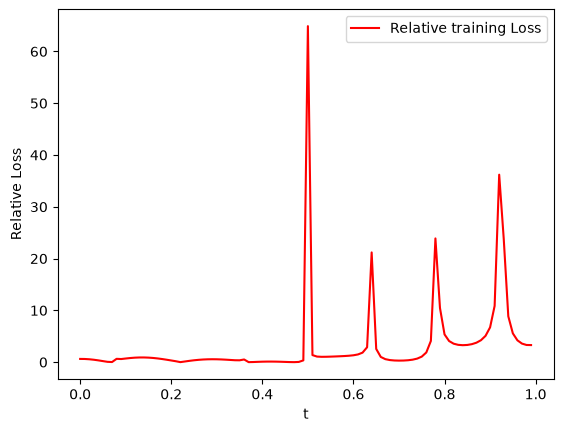

In [117]:
rval_loss = []
for i in range(len(x_val)):
    output = net(x_val[i])

    # compute gradients given loss
    target_batch = target_val[i]
    batch_loss = criterion(output, target_batch)
    rval_loss.append(batch_loss/abs(target_val[i]))

plot_loss = [loss.detach().numpy() for loss in rval_loss]
plt.figure()
plt.plot(x_val, plot_loss, 'r')
plt.legend(['Relative training Loss'])
plt.xlabel('t'), plt.ylabel('Relative Loss')

(Text(0.5, 0, 't'), Text(0, 0.5, 'x(t)'))

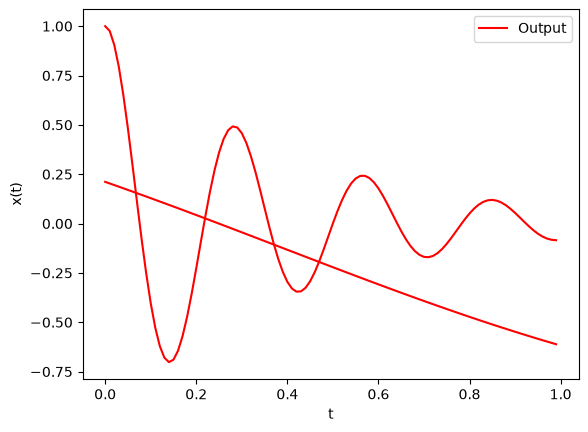

In [118]:
outputs = []
targets = []
for i in range(len(x_val)):
    output = net(x_val[i])
    outputs.append(output)
    target = x(x_val[i])
    targets.append(target)

# for o in outputs:
#     print(o.detach().numpy())

plot_output = [o.detach().numpy() for o in outputs]
plot_target = targets
plt.figure()
plt.plot(x_val, plot_output, 'r')
plt.plot(x_val, plot_target, 'r')
plt.legend(['Output'])
plt.xlabel('t'), plt.ylabel('x(t)')